#FujiFilm Instax Wide Evo vs. Digital Still Camera
## (1) Choice of Innovation and (2) Identification of a Similar Product from the Past

I chose the digital still camera as the look-alike for the Instax WIDE Evo. Functionally, both products combine chemical or physical photography with digital workflow. The Evo is a hybrid instant camera: it captures images digitally, shows them on a 3.5-inch LCD with lens and film effects applied before printing, stores them in internal memory or on a micro SD card, and then prints chosen images on instax WIDE film (Fujifilm, 2025). Digital still cameras introduced the same core changes to film photography in the late 1990s: an electronic sensor, an instant on-screen preview, removable memory, and the freedom to select, edit and share photos instead of committing every frame to film. In both cases the technology behind the product is a digital imaging pipeline built into a familiar camera form, and the value to the user comes from combining the experience of a traditional camera with digital control.

The market impact is also comparable in structure, with some differences. Digital cameras were adopted by people who already owned film cameras and understood photography, and they spread through word of mouth and visible use, which is the mix of innovation and imitation that the Bass model describes. CIPA’s worldwide shipment data show this clearly: shipments grew from about 5.1 million units in 1999 to a peak of about 121.5 million in 2010 (CIPA, 2025). The Evo targets the same kind of buyer, a person who already values a camera and now gets a digital layer on top of it, and it is a new generation within the instant-camera category rather than an entirely new one.

*References:*

*   Fujifilm. (2025, January 21). *instax WIDE Evo Hybrid InstantCamera.* https://www.fujifilm.com/fi/en/news/Fujifilm-introduce/instax-WIDE-Evo-Hybrid-Instant-Camera

*   Camera & Imaging Products Association (CIPA). (2025). *Total Shipments of Digital Still Cameras (Classified by Type).* https://www.cipa.jp/stats/documents/common/cr300.pdf

##(3) Historical Data from CIPA (2025) and Its Processing





In [7]:
#imports
import re
import pandas as pd
import pdfplumber
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


In [4]:
uploaded = files.upload()
pdf_path = next(iter(uploaded))


with pdfplumber.open(pdf_path) as pdf:
    lines = pdf.pages[0].extract_text().splitlines()

def is_number(token):
    return re.fullmatch(r"\d{1,3}(,\d{3})*|\d+", token) is not None


header_idx = next(i for i, l in enumerate(lines) if "Quantity of Total Shipments" in l)
years = [int(t) for t in lines[header_idx + 1].split()]


label_idx = next(i for i, l in enumerate(lines) if l.strip() == "Digital Still Cameras Total")
values = [int(t.replace(",", "")) for t in lines[label_idx - 1].split() if is_number(t)]

assert len(years) == len(values), f"{len(years)} years vs {len(values)} values"


df = pd.DataFrame({"year": years, "units_thousands": values})
df.to_csv("cipa_shipments.csv", index=False)
print(df)

files.download("cipa_shipments.csv")

Saving cr300.pdf to cr300 (1).pdf
    year  units_thousands
0   1999             5088
1   2000            10342
2   2001            14753
3   2002            24551
4   2003            43408
5   2004            59766
6   2005            64766
7   2006            78981
8   2007           100367
9   2008           119757
10  2009           105864
11  2010           121463
12  2011           115524
13  2012            98139
14  2013            62840
15  2014            43434
16  2015            35395
17  2016            24190
18  2017            24978
19  2018            19423
20  2019            15217
21  2020             8886
22  2021             8362
23  2022             8012
24  2023             7721
25  2024             8490
26  2025             9439


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##(4) Estimation of Bass Model Parameters


Estimated parameters of look-alike:
p: 0.009967
q: 0.381293
M: 1195308 (thousand units)
R^2: 0.969


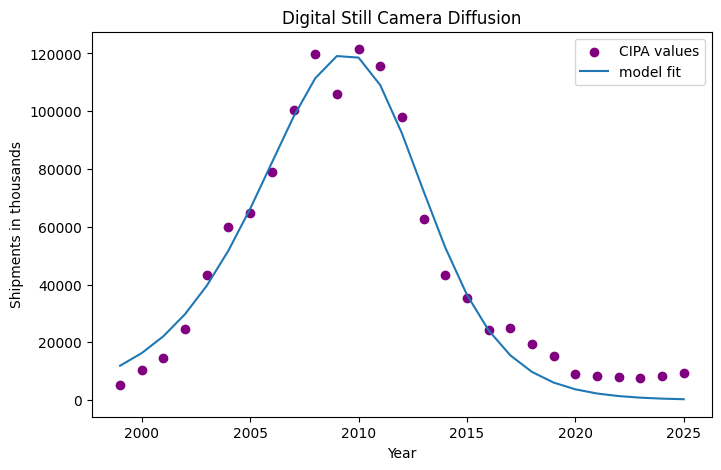

In [15]:
year_list = df['year'].values
shipments = df['units_thousands'].values
period = np.arange(1, len(shipments) + 1)

# function
def bass_sales(period, p, q, M):
    # S(t) = p*M + (q - p)*N(t-1) - (q/M)*N(t-1)^2
    predicted = np.zeros(len(period))
    total = np.zeros(len(period))

    for i in range(len(period)):
        prev_total = total[i - 1] if i > 0 else 0
        predicted[i] = p * M + (q - p) * prev_total - (q / M) * prev_total**2
        total[i] = prev_total + predicted[i]
    return predicted

# Parameter estimation
# Starting values for p, q, M (M in thousands of units)
start_values = [0.01, 0.4, 1200000]

est, _ = curve_fit(bass_sales, period, shipments, p0=start_values)
p_est, q_est, M_est = est

print(f"Estimated parameters of look-alike:\np: {p_est:.6f}\nq: {q_est:.6f}\nM: {M_est:.0f} (thousand units)")

#plotting
model_fit = bass_sales(period, p_est, q_est, M_est)
r_squared = 1 - np.sum((shipments - model_fit)**2) / np.sum((shipments - shipments.mean())**2)
print(f"R^2: {r_squared:.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(year_list, shipments, color='purple', label='CIPA values')
plt.plot(year_list, model_fit, label='model fit')
plt.title('Digital Still Camera Diffusion')
plt.xlabel('Year')
plt.ylabel('Shipments in thousands')
plt.legend()
plt.show()

*Results' analysis*

*   **p=0.01** is small, so few buyers adopt independently of others
*   **q=0.38** is much larger than p, so adoption was driven mainly by imitation and word of mouth
*   **M** is the total lifetime market of about 1.2 billion units


##(5) Predicting the Diffusion of the Innovation Selected in Step 1

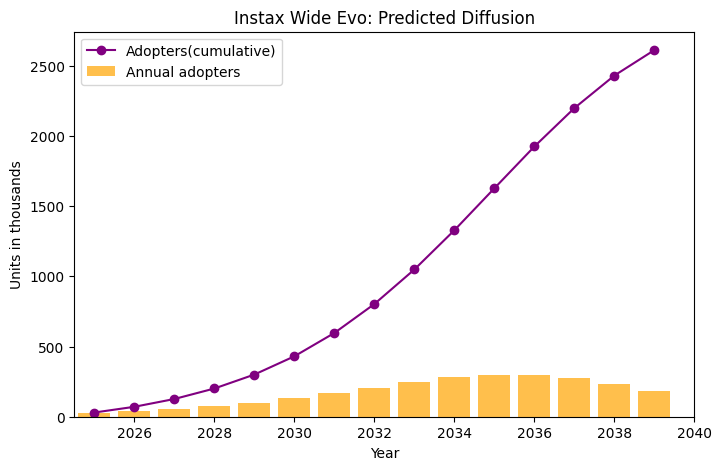

In [13]:
# Market potential for the Instax Wide Evo (in thousands of units)
# Fermi estimate: 100 million instax units sold since 1998 (Fujifilm, 2025)
# x 10% share of the WIDE format x 30% share of hybrid (Evo-type) models
M_evo = 100000 * 0.10 * 0.30   # = 3000 thousand units = 3 million

# Forecast horizon: 15 years, launch in 2025 (period 1)
future_period = np.arange(1, 16)
future_years = 2024 + future_period

# Bass forecast using p and q from the digital camera look-alike
evo_sales = bass_sales(future_period, p_est, q_est, M_evo)
evo_total = np.cumsum(evo_sales)

# Plot
plt.figure(figsize=(8, 5))
plt.bar(future_years, evo_sales, color='orange', alpha=0.7, label='Annual adopters')
plt.plot(future_years, evo_total, color='purple', marker='o', label='Adopters(cumulative)')
plt.xlim(2024.5, 2040)
plt.title('Instax Wide Evo: Predicted Diffusion')
plt.xlabel('Year')
plt.ylabel('Units in thousands')
plt.legend()
plt.show()

Using the look-alike parameters (p = 0.01, q = 0.38) and a market potential of 3 million units, the model predicts slow initial adoption followed by a peak of about 300 thousand units per year around 2035-2036. By 2039 cumulative adopters reach about 2.6 million, roughly 87% of the market potential, so the market is approaching saturation. The result is driven mostly by word-of-mouth imitation, consistent with the digital camera pattern.

## (6) Choice of Scope

I analyze the diffusion of the Instax WIDE Evo at the global level, for three reasons:

1.   The market is international. Fujifilm describes instax as a global brand available in more than 100 countries and regions (Fujifilm, 2025). A single-country analysis would therefore capture only a small part of the market.
2.   The look-alike data is global. The CIPA digital still camera shipments used to estimate p and q cover worldwide shipments (CIPA, 2025). Applying the parameters to a global forecast keeps the scope consistent between the look-alike and the new product.
3. The market potential is built from global data. The M estimate starts from Fujifilm’s worldwide cumulative instax sales of more than 100 million units (Fujifilm, 2025), which are not available by country.


*References:*

*   Camera & Imaging Products Association (CIPA). (2025). *Total shipments of digital still cameras (classified by type).* https://www.cipa.jp/stats/documents/common/cr300.pdf
* Fujifilm Corporation. (2025, April 8). *instax cumulative sales exceeds 100 million units.* https://www.fujifilm.com/jp/en/news/hq/12295



## (7) Estimation of the Number of Adopters per Period

In [14]:
# Adopters by period (thousands of units)
adopters_table = pd.DataFrame({
    'Year': future_years,
    'Period': future_period,
    'Annual_Adopters': evo_sales.round(0),
    'Cumulative_Adopters': evo_total.round(0),
    'Share_of_M_%': (evo_total / M_evo * 100).round(1)
})

print(adopters_table.to_string(index=False))

adopters_table.to_csv('evo_adopters_forecast.csv', index=False)

 Year  Period  Annual_Adopters  Cumulative_Adopters  Share_of_M_%
 2025       1             30.0                 30.0           1.0
 2026       2             41.0                 71.0           2.4
 2027       3             56.0                126.0           4.2
 2028       4             75.0                201.0           6.7
 2029       5             99.0                301.0          10.0
 2030       6            130.0                431.0          14.4
 2031       7            166.0                597.0          19.9
 2032       8            206.0                803.0          26.8
 2033       9            246.0               1049.0          35.0
 2034      10            280.0               1329.0          44.3
 2035      11            299.0               1628.0          54.3
 2036      12            298.0               1925.0          64.2
 2037      13            274.0               2199.0          73.3
 2038      14            232.0               2431.0          81.0
 2039     

*Results' Analysis*
*   Adoption starts slowly: about 30 thousand adopters in 2025 and 100 thousand per year by 2029.
*   Annual adoption then grows steadily and peaks in 2035 at about 299 thousand units.
* After the peak, annual adoption declines, reaching about 182 thousand by 2039, because fewer potential buyers remain.
* Cumulative adopters reach about 2.6 million units by 2039, which is 87% of the assumed market potential of 3 million.
* The pattern is driven mostly by word-of-mouth imitation (q = 0.38 is much larger than p = 0.01), as it was for digital still cameras.
* The timing of the peak depends only on p and q, but the number of adopters scales with the assumed M.
